In [ ]:
!pip install geopandas rasterio matplotlib shapely

CRS: EPSG:4326
Features: 1
Geometry: ['Polygon']


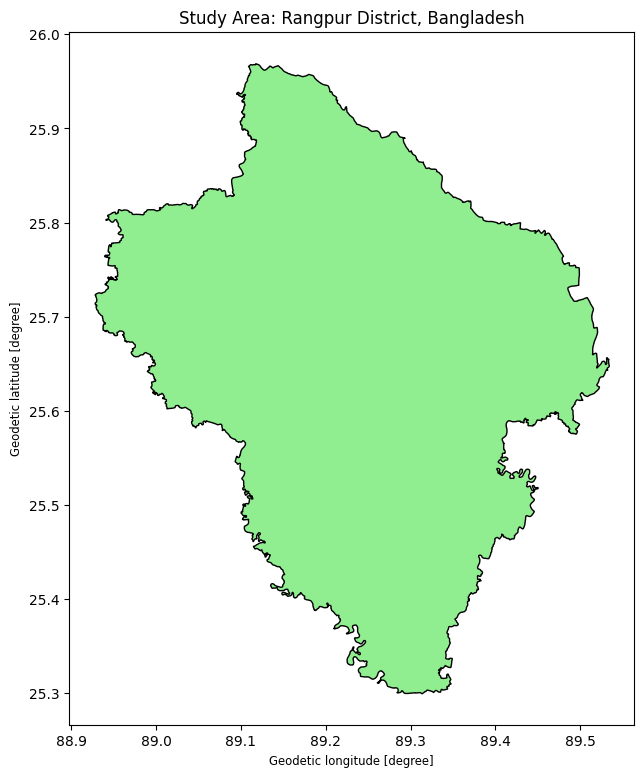

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Load Rangpur boundary
rangpur = gpd.read_file(
    "/content/RANGPUR_BOUNDARY.shp"
)

# Check information
print("CRS:", rangpur.crs)
print("Features:", len(rangpur))
print("Geometry:", rangpur.geom_type.tolist())

# Plot boundary
fig, ax = plt.subplots(figsize=(8, 9))

rangpur.plot(
    ax=ax,
    facecolor="lightgreen",
    edgecolor="black"
)

ax.set_title(
    "Study Area: Rangpur District, Bangladesh"
)

plt.show()

In [ ]:
import rasterio
from rasterio.mask import mask
from shapely.geometry import mapping

raster_files = {
    "NDVI": "/content/ndvi_rangpur.tif",
    "NDWI": "/content/ndwi_rangpur.tif",
    "DEM": "/content/dem_rangpur.tif"
}

for name, path in raster_files.items():

    with rasterio.open(path) as src:
        # Reproject boundary to match the raster's CRS
        rangpur_reprojected = rangpur.to_crs(src.crs)

        geometries = [
            mapping(geom)
            for geom in rangpur_reprojected.geometry
        ]

        clipped, transform = mask(
            src,
            geometries,
            crop=True,
            filled=True,
            nodata=src.nodata if src.nodata is not None else -9999
        )

        metadata = src.meta.copy()

        metadata.update({
            "height": clipped.shape[1],
            "width": clipped.shape[2],
            "transform": transform,
            "nodata": src.nodata if src.nodata is not None else -9999
        })

        output = f"/content/Rangpur_{name}_Clipped.tif"

        with rasterio.open(
            output,
            "w",
            **metadata
        ) as dest:

            dest.write(clipped)

    print(name, "successfully clipped:", output)

NDVI successfully clipped: /content/Rangpur_NDVI_Clipped.tif
NDWI successfully clipped: /content/Rangpur_NDWI_Clipped.tif
DEM successfully clipped: /content/Rangpur_DEM_Clipped.tif


/usr/local/lib/python3.13/dist-packages/matplotlib/colors.py:2294: RuntimeWarning: overflow encountered in divide
  resdat /= (vmax - vmin)


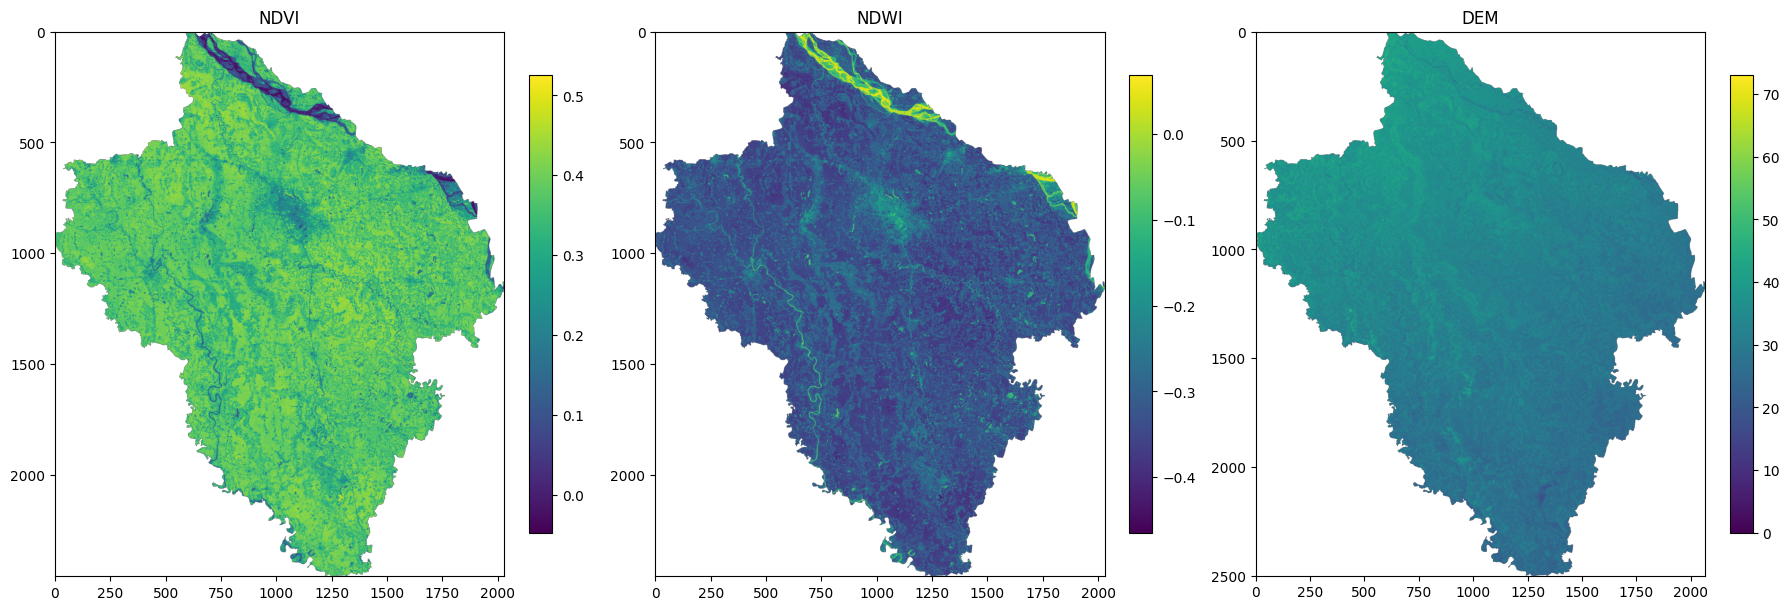

In [ ]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 7)
)

for ax, name in zip(
    axes,
    ["NDVI", "NDWI", "DEM"]
):

    with rasterio.open(
        f"/content/Rangpur_{name}_Clipped.tif"
    ) as src:

        data = src.read(1, masked=True)

        im = ax.imshow(data)

        ax.set_title(name)

        plt.colorbar(
            im,
            ax=ax,
            fraction=0.046
        )

plt.tight_layout()
plt.show()

In [ ]:

import pandas as pd

data = [
    ["REC-001", "1892-1902", "Mahiganj", "All causes (General Mortality)",
     42.2, "Deaths per 1,000",
     "Marshy thana; moribund channels of Ghaghat river; stagnant pools and excessive humidity",
     "50", "Quantitative", "Location-specific"],

    ["REC-004", "1892-1902", "Historical Rangpur District", "All causes",
     31.62, "Deaths per 1,000",
     "Heavy rainfall; imperfect natural drainage; village pits and borrow-pits",
     "49-50", "Quantitative", "District-wide historical context"],

    ["REC-005", "1903-1907", "Historical Rangpur District", "All causes",
     33.18, "Deaths per 1,000",
     "Rainfall fluctuations; mortality variations associated with rainfall",
     "49-50", "Quantitative", "District-wide historical context"],

    ["REC-006", "1904-1908", "Historical Rangpur District", "All causes",
     34.2, "Deaths per 1,000",
     "Quinquennial district mortality",
     "50", "Quantitative", "District-wide historical context"],

    ["REC-007", "1899-1908", "Historical Rangpur District", "Fever (Malarial fever)",
     29.23, "Deaths per 1,000",
     "Swamps and marshes in deserted river courses; mosquito breeding environments",
     "50-51", "Quantitative", "District-wide historical context"],

    ["REC-008", "1893-1902", "Historical Rangpur District", "Fever",
     28.6, "Deaths per 1,000",
     "Ill-drained depressions; shallow tanks; dense jungle around huts",
     "51", "Quantitative", "District-wide historical context"],

    ["REC-009", "1900-1904", "Historical Rangpur District", "Fever",
     29.0, "Deaths per 1,000",
     "Moist and humid conditions following the monsoon",
     "51", "Quantitative", "District-wide historical context"],

    ["REC-010", "1904-1908", "Historical Rangpur District", "Fever",
     30.6, "Deaths per 1,000",
     "Post-monsoon and winter prevalence of historical fever types",
     "51", "Quantitative", "District-wide historical context"],

    ["REC-011", "1893-1902", "Historical Rangpur District", "Cholera",
     1.0, "Deaths per 1,000",
     "Polluted drinking water; unprotected wells and tanks",
     "51-52", "Quantitative", "District-wide historical context"],

    ["REC-012", "1899-1908", "Historical Rangpur District", "Cholera",
     1.2, "Deaths per 1,000",
     "Endemic disease with seasonal epidemic outbreaks",
     "51-52", "Quantitative", "District-wide historical context"],

    ["REC-013", "1904-1908", "Rangpur Headquarters Town", "All causes",
     19.9, "Deaths per 1,000",
     "Drainage improvements and healthier urban conditions",
     "49", "Quantitative", "Location-specific"],

    ["REC-014", "1908", "Rangpur Headquarters Town", "All causes",
     15.5, "Deaths per 1,000",
     "Improved drainage and municipal sanitary oversight",
     "150", "Quantitative", "Location-specific"],

    ["REC-015", "1904-1908", "Historical Rangpur District", "Smallpox",
     0.36, "Deaths per 1,000",
     "Vaccination and rural public health conditions",
     "53", "Quantitative", "District-wide historical context"],

    ["REC-018", "1891-1901", "Mahiganj", "Malaria",
     None, "Population decrease",
     "Stagnant Ghaghat riverbed; extensive marshes and decaying vegetation",
     "36, 151", "Qualitative", "Location-specific"],

    ["REC-020", "1894-1896", "Historical Rangpur District", "All causes",
     223034, "Total recorded deaths",
     "Obstructed riverbeds; stagnant watercourses; historical malaria incidence",
     "35, 78", "Quantitative", "District-wide historical context"],

    ["REC-021", "1898-1900", "Historical Rangpur District", "All causes",
     190883, "Total recorded deaths",
     "Post-earthquake changes in drainage and surface runoff",
     "35, 78", "Quantitative", "District-wide historical context"]
]

columns = [
    "Record_ID",
    "Historical_Year",
    "Location",
    "Disease",
    "Mortality_Rate",
    "Unit",
    "Environmental_Observation",
    "Source_Page",
    "Evidence_Type",
    "Spatial_Use"
]

df = pd.DataFrame(data, columns=columns)

# Export CSV
df.to_csv(
    "/content/rangpur_historical_data.csv",
    index=False
)

# Display dataset
display(df)

print("Total records:", len(df))
print("CSV successfully created!")


,Record_ID,Historical_Year,Location,Disease,Mortality_Rate,Unit,Environmental_Observation,Source_Page,Evidence_Type,Spatial_Use
0,REC-001,1892-1902,Mahiganj,All causes (General Mortality),42.20,"Deaths per 1,000",Marshy thana; moribund channels of Ghaghat riv...,50,Quantitative,Location-specific
1,REC-004,1892-1902,Historical Rangpur District,All causes,31.62,"Deaths per 1,000",Heavy rainfall; imperfect natural drainage; vi...,49-50,Quantitative,District-wide historical context
2,REC-005,1903-1907,Historical Rangpur District,All causes,33.18,"Deaths per 1,000",Rainfall fluctuations; mortality variations as...,49-50,Quantitative,District-wide historical context
3,REC-006,1904-1908,Historical Rangpur District,All causes,34.20,"Deaths per 1,000",Quinquennial district mortality,50,Quantitative,District-wide historical context
4,REC-007,1899-1908,Historical Rangpur District,Fever (Malarial fever),29.23,"Deaths per 1,000",Swamps and marshes in deserted river courses; ...,50-51,Quantitative,District-wide historical context
5,REC-008,1893-1902,Historical Rangpur District,Fever,28.60,"Deaths per 1,000",Ill-drained depressions; shallow tanks; dense ...,51,Quantitative,District-wide historical context
6,REC-009,1900-1904,Historical Rangpur District,Fever,29.00,"Deaths per 1,000",Moist and humid conditions following the monsoon,51,Quantitative,District-wide historical context
7,REC-010,1904-1908,Historical Rangpur District,Fever,30.60,"Deaths per 1,000",Post-monsoon and winter prevalence of historic...,51,Quantitative,District-wide historical context
8,REC-011,1893-1902,Historical Rangpur District,Cholera,1.00,"Deaths per 1,000",Polluted drinking water; unprotected wells and...,51-52,Quantitative,District-wide historical context
9,REC-012,1899-1908,Historical Rangpur District,Cholera,1.20,"Deaths per 1,000",Endemic disease with seasonal epidemic outbreaks,51-52,Quantitative,District-wide historical context


Total records: 16
CSV successfully created!


In [ ]:
import pandas as pd
import geopandas as gpd

# Read geographical CSV
locations = pd.read_csv(
    "/content/rangpur_historical_data.csv"
)

# Define coordinate mapping for known locations
# (Latitude, Longitude) for Rangpur, Bangladesh region
coordinates_map = {
    "Mahiganj": (25.7285, 89.2842),
    "Rangpur Headquarters Town": (25.7538, 89.2467),
    "Historical Rangpur District": (25.7500, 89.2500) # Region centroid
}

# Map coordinates to the locations
locations["Latitude"] = locations["Location"].map(lambda loc: coordinates_map.get(loc, (None, None))[0])
locations["Longitude"] = locations["Location"].map(lambda loc: coordinates_map.get(loc, (None, None))[1])

# Keep records with verified coordinates
locations = locations.dropna(
    subset=["Latitude", "Longitude"]
)

# Convert into geographical points
geo_locations = gpd.GeoDataFrame(
    locations,
    geometry=gpd.points_from_xy(
        locations["Longitude"],
        locations["Latitude"
    ]),
    crs="EPSG:4326"
)

# Reproject to match Rangpur raster data (UTM Zone 45N)
geo_locations = geo_locations.to_crs(
    "EPSG:32645"
)

print(geo_locations.head())

  Record_ID Historical_Year                     Location  \
0   REC-001       1892-1902                     Mahiganj   
1   REC-004       1892-1902  Historical Rangpur District   
2   REC-005       1903-1907  Historical Rangpur District   
3   REC-006       1904-1908  Historical Rangpur District   
4   REC-007       1899-1908  Historical Rangpur District   

                          Disease  Mortality_Rate              Unit  \
0  All causes (General Mortality)           42.20  Deaths per 1,000   
1                      All causes           31.62  Deaths per 1,000   
2                      All causes           33.18  Deaths per 1,000   
3                      All causes           34.20  Deaths per 1,000   
4          Fever (Malarial fever)           29.23  Deaths per 1,000   

                           Environmental_Observation Source_Page  \
0  Marshy thana; moribund channels of Ghaghat riv...          50   
1  Heavy rainfall; imperfect natural drainage; vi...       49-50   
2  Rainf

In [ ]:
import pandas as pd
import geopandas as gpd

# Your original dataframe
df = pd.read_csv("/content/rangpur_historical_data.csv")

# Dataset A: Location-specific records
location_df = df[
    df["Spatial_Use"] == "Location-specific"
].copy()

# Dataset B: District-wide records
district_df = df[
    df["Spatial_Use"] == "District-wide historical context"
].copy()

# District-wide records should not have arbitrary coordinates
if "Latitude" in district_df.columns:
    district_df["Latitude"] = None
    district_df["Longitude"] = None

print("Location-specific records:")
display(location_df)

print("District-wide records:")
display(district_df)

Location-specific records:


,Record_ID,Historical_Year,Location,Disease,Mortality_Rate,Unit,Environmental_Observation,Source_Page,Evidence_Type,Spatial_Use
0,REC-001,1892-1902,Mahiganj,All causes (General Mortality),42.2,"Deaths per 1,000",Marshy thana; moribund channels of Ghaghat riv...,50,Quantitative,Location-specific
10,REC-013,1904-1908,Rangpur Headquarters Town,All causes,19.9,"Deaths per 1,000",Drainage improvements and healthier urban cond...,49,Quantitative,Location-specific
11,REC-014,1908,Rangpur Headquarters Town,All causes,15.5,"Deaths per 1,000",Improved drainage and municipal sanitary overs...,150,Quantitative,Location-specific
13,REC-018,1891-1901,Mahiganj,Malaria,NaN,Population decrease,Stagnant Ghaghat riverbed; extensive marshes a...,"36, 151",Qualitative,Location-specific


District-wide records:


,Record_ID,Historical_Year,Location,Disease,Mortality_Rate,Unit,Environmental_Observation,Source_Page,Evidence_Type,Spatial_Use
1,REC-004,1892-1902,Historical Rangpur District,All causes,31.62,"Deaths per 1,000",Heavy rainfall; imperfect natural drainage; vi...,49-50,Quantitative,District-wide historical context
2,REC-005,1903-1907,Historical Rangpur District,All causes,33.18,"Deaths per 1,000",Rainfall fluctuations; mortality variations as...,49-50,Quantitative,District-wide historical context
3,REC-006,1904-1908,Historical Rangpur District,All causes,34.20,"Deaths per 1,000",Quinquennial district mortality,50,Quantitative,District-wide historical context
4,REC-007,1899-1908,Historical Rangpur District,Fever (Malarial fever),29.23,"Deaths per 1,000",Swamps and marshes in deserted river courses; ...,50-51,Quantitative,District-wide historical context
5,REC-008,1893-1902,Historical Rangpur District,Fever,28.60,"Deaths per 1,000",Ill-drained depressions; shallow tanks; dense ...,51,Quantitative,District-wide historical context
6,REC-009,1900-1904,Historical Rangpur District,Fever,29.00,"Deaths per 1,000",Moist and humid conditions following the monsoon,51,Quantitative,District-wide historical context
7,REC-010,1904-1908,Historical Rangpur District,Fever,30.60,"Deaths per 1,000",Post-monsoon and winter prevalence of historic...,51,Quantitative,District-wide historical context
8,REC-011,1893-1902,Historical Rangpur District,Cholera,1.00,"Deaths per 1,000",Polluted drinking water; unprotected wells and...,51-52,Quantitative,District-wide historical context
9,REC-012,1899-1908,Historical Rangpur District,Cholera,1.20,"Deaths per 1,000",Endemic disease with seasonal epidemic outbreaks,51-52,Quantitative,District-wide historical context
12,REC-015,1904-1908,Historical Rangpur District,Smallpox,0.36,"Deaths per 1,000",Vaccination and rural public health conditions,53,Quantitative,District-wide historical context


In [ ]:
location_df.to_csv(
    "/content/location_specific_records.csv",
    index=False
)

district_df.to_csv(
    "/content/district_wide_records.csv",
    index=False
)

In [ ]:
# Load district boundary
boundary = gpd.read_file(
    "/content/RANGPUR_BOUNDARY.shp"
)

# Define coordinate mapping for known locations
coordinates_map = {
    "Mahiganj": (25.7285, 89.2842),
    "Rangpur Headquarters Town": (25.7538, 89.2467)
}

# Map coordinates to location_df
location_df["Latitude"] = location_df["Location"].map(lambda loc: coordinates_map.get(loc, (None, None))[0])
location_df["Longitude"] = location_df["Location"].map(lambda loc: coordinates_map.get(loc, (None, None))[1])

# Keep records with verified coordinates
location_df_clean = location_df.dropna(subset=["Latitude", "Longitude"]).copy()

# Convert location data into GeoDataFrame
geo_locations = gpd.GeoDataFrame(
    location_df_clean,
    geometry=gpd.points_from_xy(
        location_df_clean["Longitude"],
        location_df_clean["Latitude"]
    ),
    crs="EPSG:4326"
)

# Match coordinate systems
geo_locations = geo_locations.to_crs(
    boundary.crs
)

# Check whether points fall inside boundary
geo_locations["Inside_Rangpur"] = (
    geo_locations.geometry.apply(
        lambda point: boundary.geometry.contains(point).any()
    )
)

display(
    geo_locations[
        ["Record_ID", "Location",
         "Inside_Rangpur", "geometry"]
    ]
)

,Record_ID,Location,Inside_Rangpur,geometry
0,REC-001,Mahiganj,True,POINT (89.2842 25.7285)
10,REC-013,Rangpur Headquarters Town,True,POINT (89.2467 25.7538)
11,REC-014,Rangpur Headquarters Town,True,POINT (89.2467 25.7538)
13,REC-018,Mahiganj,True,POINT (89.2842 25.7285)


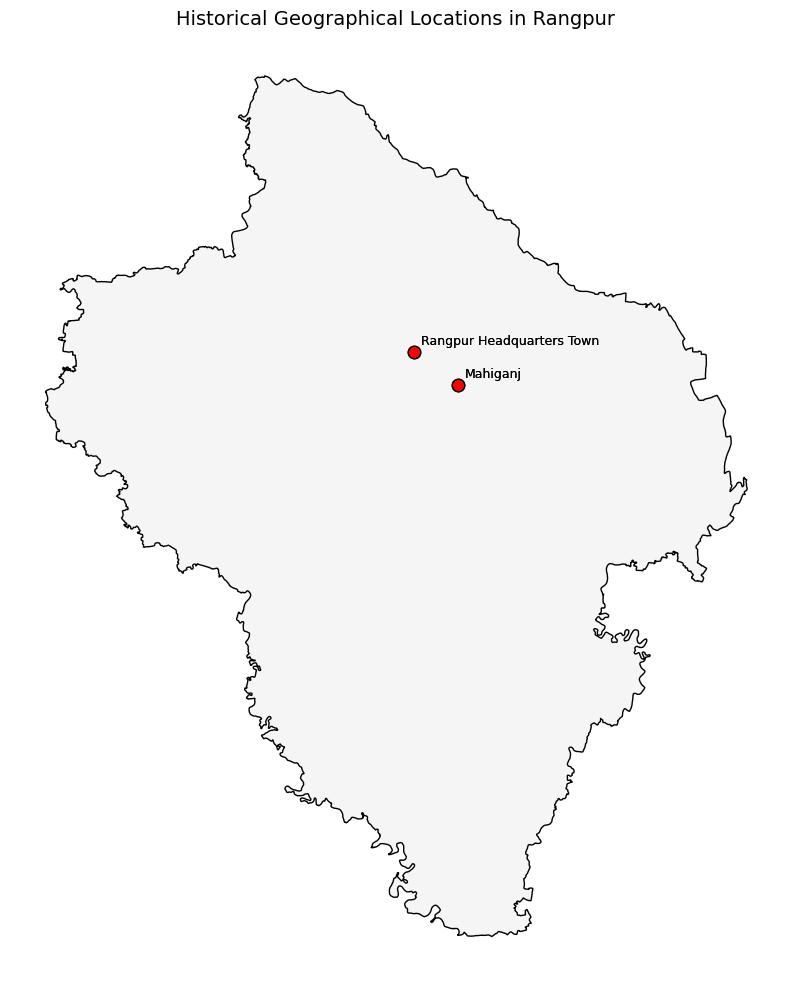

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

# Plot Rangpur boundary
boundary.plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="black",
    linewidth=1
)

# Plot historical locations
geo_locations.plot(
    ax=ax,
    color="red",
    edgecolor="black",
    markersize=80
)

# Add location labels
for _, row in geo_locations.iterrows():

    ax.annotate(
        row["Location"],
        xy=(row.geometry.x, row.geometry.y),
        xytext=(5, 6),
        textcoords="offset points",
        fontsize=9
    )

ax.set_title(
    "Historical Geographical Locations in Rangpur",
    fontsize=14
)

ax.set_axis_off()

plt.tight_layout()

plt.savefig(
    "/content/historical_locations_rangpur.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import pandas as pd
import geopandas as gpd

# Load location-specific records
location_df = pd.read_csv(
    "/content/location_specific_records.csv"
)

# Define coordinate mapping for known locations
coordinates_map = {
    "Mahiganj": (25.7285, 89.2842),
    "Rangpur Headquarters Town": (25.7538, 89.2467)
}

# Map coordinates back onto the dataframe
location_df["Latitude"] = location_df["Location"].map(lambda loc: coordinates_map.get(loc, (None, None))[0])
location_df["Longitude"] = location_df["Location"].map(lambda loc: coordinates_map.get(loc, (None, None))[1])

# Remove records without coordinates
location_df = location_df.dropna(
    subset=["Latitude", "Longitude"]
)

# Convert to GeoDataFrame
geo_locations = gpd.GeoDataFrame(
    location_df,
    geometry=gpd.points_from_xy(
        location_df["Longitude"],
        location_df["Latitude"]
    ),
    crs="EPSG:4326"
)

print("Number of geographical locations:", len(geo_locations))
display(geo_locations)

Number of geographical locations: 4


,Record_ID,Historical_Year,Location,Disease,Mortality_Rate,Unit,Environmental_Observation,Source_Page,Evidence_Type,Spatial_Use,Latitude,Longitude,geometry
0,REC-001,1892-1902,Mahiganj,All causes (General Mortality),42.2,"Deaths per 1,000",Marshy thana; moribund channels of Ghaghat riv...,50,Quantitative,Location-specific,25.7285,89.2842,POINT (89.2842 25.7285)
1,REC-013,1904-1908,Rangpur Headquarters Town,All causes,19.9,"Deaths per 1,000",Drainage improvements and healthier urban cond...,49,Quantitative,Location-specific,25.7538,89.2467,POINT (89.2467 25.7538)
2,REC-014,1908,Rangpur Headquarters Town,All causes,15.5,"Deaths per 1,000",Improved drainage and municipal sanitary overs...,150,Quantitative,Location-specific,25.7538,89.2467,POINT (89.2467 25.7538)
3,REC-018,1891-1901,Mahiganj,Malaria,NaN,Population decrease,Stagnant Ghaghat riverbed; extensive marshes a...,"36, 151",Qualitative,Location-specific,25.7285,89.2842,POINT (89.2842 25.7285)


In [ ]:

import rasterio
import numpy as np
import pandas as pd
import geopandas as gpd

from rasterio.mask import mask
from shapely.geometry import mapping

raster_paths = {
    "NDVI": "/content/Rangpur_NDVI_Clipped.tif",
    "NDWI": "/content/Rangpur_NDWI_Clipped.tif",
    "Elevation": "/content/Rangpur_DEM_Clipped.tif"
}

results = []

for _, location in geo_locations.iterrows():

    result = {
        "Record_ID": location["Record_ID"],
        "Location": location["Location"],
        "Latitude": location["Latitude"],
        "Longitude": location["Longitude"]
    }

    for variable, path in raster_paths.items():

        with rasterio.open(path) as src:

            # Transform point to raster CRS
            point = gpd.GeoSeries(
                [location.geometry],
                crs=geo_locations.crs
            ).to_crs(src.crs).iloc[0]

            # Extract value beneath the point
            sampled = list(
                src.sample([(point.x, point.y)], masked=True)
            )[0][0]

            if np.ma.is_masked(sampled):
                point_value = np.nan
            else:
                point_value = float(sampled)

                if src.nodata is not None and point_value == src.nodata:
                    point_value = np.nan

            # Create 1 km buffer in projected metres
            buffer = point.buffer(1000)

            try:
                buffer_data, _ = mask(
                    src,
                    [mapping(buffer)],
                    crop=True,
                    filled=False
                )

                values = buffer_data[0].compressed()

                # Remove invalid values
                values = values[np.isfinite(values)]

                buffer_mean = (
                    float(np.mean(values))
                    if len(values) > 0
                    else np.nan
                )

                valid_pixels = len(values)

            except ValueError:
                buffer_mean = np.nan
                valid_pixels = 0

            result[f"{variable}_Point"] = point_value
            result[f"{variable}_BufferMean_1km"] = buffer_mean
            result[f"{variable}_ValidPixels_1km"] = valid_pixels

    results.append(result)

environmental_df = pd.DataFrame(results)

display(environmental_df)

environmental_df.to_csv(
    "/content/rangpur_environmental_extraction.csv",
    index=False
)

print("Environmental extraction completed!")


,Record_ID,Location,Latitude,Longitude,NDVI_Point,NDVI_BufferMean_1km,NDVI_ValidPixels_1km,NDWI_Point,NDWI_BufferMean_1km,NDWI_ValidPixels_1km,Elevation_Point,Elevation_BufferMean_1km,Elevation_ValidPixels_1km
0,REC-001,Mahiganj,25.7285,89.2842,0.265195,0.299684,3487,-0.225904,-0.264671,3487,34.0,35.124897,3587
1,REC-013,Rangpur Headquarters Town,25.7538,89.2467,0.209555,0.234214,3485,-0.187449,-0.211254,3485,38.0,36.526844,3595
2,REC-014,Rangpur Headquarters Town,25.7538,89.2467,0.209555,0.234214,3485,-0.187449,-0.211254,3485,38.0,36.526844,3595
3,REC-018,Mahiganj,25.7285,89.2842,0.265195,0.299684,3487,-0.225904,-0.264671,3487,34.0,35.124897,3587


Environmental extraction completed!


In [ ]:
import geopandas as gpd
import glob
import os

# Find available shapefiles
shapefiles = glob.glob(
    "/content/**/*.shp",
    recursive=True
)

for file in shapefiles:
    print(file)

/content/RANGPUR_BOUNDARY.shp
/content/HydroRIVERS_v10_as.shp


In [ ]:
# 1. Clear out the corrupted files
!rm -f /content/HydroRIVERS_v10_as.*

# 2. Download the original zip file directly from HydroSHEDS servers
!wget -O /content/HydroRIVERS_v10_as_shp.zip https://data.hydrosheds.org/file/hydrosheds-v1-rivers/hydrochannels/HydroRIVERS_v10_as_shp.zip

# 3. Unzip it directly into the /content/ folder
!unzip /content/HydroRIVERS_v10_as_shp.zip -d /content/

# 4. Clean up the zip file to save space
!rm -f /content/HydroRIVERS_v10_as_shp.zip

--2026-11-10 19:22:35--  https://data.hydrosheds.org/file/hydrosheds-v1-rivers/hydrochannels/HydroRIVERS_v10_as_shp.zip
Resolving data.hydrosheds.org (data.hydrosheds.org)... 172.67.158.28, 104.21.14.61, 2606:4700:3032::ac43:9e1c, ...
Connecting to data.hydrosheds.org (data.hydrosheds.org)|172.67.158.28|:443... connected.
HTTP request sent, awaiting response... 404 Not Found
2026-11-10 19:22:35 ERROR 404: Not Found.

Archive:  /content/HydroRIVERS_v10_as_shp.zip
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of /content/HydroRIVERS_v10_as_shp.zip or
        /content/HydroRIVERS_v10_as_shp.zip.zip, and cannot find /content/HydroRIVERS_v10_as_shp.zip.ZIP, period.


In [ ]:
river_path = "/content/HydroRIVERS_v10_as.shp"

rivers = gpd.read_file(river_path)

print("CRS:", rivers.crs)
print("Number of river features:", len(rivers))
print(rivers.head())

DataSourceError: /content/HydroRIVERS_v10_as.shp: No such file or directory

In [ ]:
# Load Rangpur boundary
boundary = gpd.read_file(
    "/content/RANGPUR_BOUNDARY.shp"
)

# Reproject both datasets
boundary = boundary.to_crs("EPSG:32645")
rivers = rivers.to_crs("EPSG:32645")

# Clip rivers
rangpur_rivers = gpd.clip(
    rivers,
    boundary
)

print("Rivers inside Rangpur:", len(rangpur_rivers))

# Save clipped river network
rangpur_rivers.to_file(
    "/content/rangpur_rivers.gpkg",
    driver="GPKG"
)

print("River clipping completed!")

NameError: name 'rivers' is not defined

In [ ]:
# Load historical geographical locations
geo_locations = gpd.read_file(
    "/content/historical_locations.gpkg"
)

# Ensure same projected CRS
geo_locations = geo_locations.to_crs(
    "EPSG:32645"
)

rangpur_rivers = rangpur_rivers.to_crs(
    "EPSG:32645"
)

# Calculate nearest river distance
river_analysis = gpd.sjoin_nearest(
    geo_locations,
    rangpur_rivers,
    how="left",
    distance_col="Distance_to_River_m"
)

# Convert metres into kilometres
river_analysis["Distance_to_River_km"] = (
    river_analysis["Distance_to_River_m"] / 1000
)

display(
    river_analysis[
        [
            "Record_ID",
            "Location",
            "Distance_to_River_m",
            "Distance_to_River_km"
        ]
    ]
)

DataSourceError: /content/historical_locations.gpkg: No such file or directory

In [ ]:
geo_locations.to_file(
    "/content/historical_locations.gpkg",
    driver="GPKG"
)

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

boundary.plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="black"
)

rangpur_rivers.plot(
    ax=ax,
    color="blue",
    linewidth=0.6
)

river_analysis.plot(
    ax=ax,
    color="red",
    markersize=60,
    edgecolor="black"
)

for _, row in river_analysis.iterrows():

    ax.annotate(
        row["Location"],
        xy=(row.geometry.x, row.geometry.y),
        xytext=(5, 5),
        textcoords="offset points"
    )

ax.set_title(
    "Historical Locations and River Network – Rangpur"
)

ax.set_axis_off()

plt.tight_layout()

plt.savefig(
    "/content/rangpur_river_proximity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
river_analysis.drop(
    columns="geometry"
).to_csv(
    "/content/rangpur_river_distance.csv",
    index=False
)